# CSE-532 — Final Project: Customer Segmentation and Purchasing Behavior Analysis
**Lejla Setka · Fall 2026**  
**Research focus:** RFM-based customer clustering, visual group membership, model quality, stability, and interpretability.

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (Chen, 2015, DOI: 10.24432/C5BW33). Data cover December 2010 to December 2011; dataset license CC BY 4.0.

**Reproduction:** Place `Online Retail.xlsx` beside this notebook, install packages listed in `requirements.txt`, then run all cells in order. Results and charts are generated from authentic data, not prefilled. This notebook extends the earlier midpoint notebook.

## 0 · Setup
Download **Online Retail.xlsx** from the UCI page and put it in the **same folder** as this notebook. Install packages using `%pip install pandas openpyxl numpy matplotlib seaborn scikit-learn` in Jupyter if needed.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH = Path("Online Retail.xlsx")
assert DATA_PATH.exists(), "Download 'Online Retail.xlsx' from UCI and place it beside this notebook."
raw = pd.read_excel(DATA_PATH, engine="openpyxl")
print("Raw shape:", raw.shape)
print("Date range:", raw["InvoiceDate"].min(), "to", raw["InvoiceDate"].max())
display(raw.head())

Raw shape: (541909, 8)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1 · Initial exploration and quality checks
Record the printed numbers for your *Dataset & Data Quality* slide.

In [2]:
print("Column types:")
print(raw.dtypes)
print("\nMissing entries by column:")
print(raw.isna().sum().sort_values(ascending=False))
print("\nDuplicate full rows:", raw.duplicated().sum())
print("Distinct customer IDs:", raw["CustomerID"].nunique())
print("Distinct invoices:", raw["InvoiceNo"].nunique())
print("Distinct countries:", raw["Country"].nunique())

cancellation = raw["InvoiceNo"].astype(str).str.upper().str.startswith("C")
print("Cancellation line items:", cancellation.sum())
print("Nonpositive quantity:", (raw["Quantity"] <= 0).sum())
print("Nonpositive price:", (raw["UnitPrice"] <= 0).sum())

Column types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing entries by column:
CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64



Duplicate full rows: 5268
Distinct customer IDs: 4372
Distinct invoices: 25900
Distinct countries: 38
Cancellation line items: 9288
Nonpositive quantity: 10624
Nonpositive price: 2517


## 2 · Cleaning decisions
Customer-level RFM requires a valid `CustomerID`. The initial purchase-only model excludes cancellations and rows with nonpositive quantity or price; cancellations are **retained separately** as a descriptive feature. We remove exact duplicate rows, but this assumes identical duplicate records are accidental, which we should state as a limitation.

**Methodological caution:** Cancellation counts and sales amounts are **not** equated with refunds; an invoice line starting with `C` denotes a cancellation. The raw dataset cannot always establish full return/refund history.

In [3]:
df = raw.drop_duplicates().copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
valid_customers = df.dropna(subset=["CustomerID", "InvoiceDate"]).copy()
valid_customers["CustomerID"] = valid_customers["CustomerID"].astype(int).astype(str)
valid_customers["IsCancellation"] = valid_customers["InvoiceNo"].str.upper().str.startswith("C")

cancel_counts = (valid_customers.groupby("CustomerID")["IsCancellation"]
                 .sum().rename("CancellationLineCount"))

purchases = valid_customers.loc[
    ~valid_customers["IsCancellation"]
    & (valid_customers["Quantity"] > 0)
    & (valid_customers["UnitPrice"] > 0)
].copy()
purchases["Revenue"] = purchases["Quantity"] * purchases["UnitPrice"]
print("Original line items:", len(raw))
print("After deduplication:", len(df))
print("Rows with customer ID and valid date:", len(valid_customers))
print("Valid purchase line items:", len(purchases))
print("Customers with valid purchases:", purchases["CustomerID"].nunique())

Original line items: 541909
After deduplication: 536641
Rows with customer ID and valid date: 401604
Valid purchase line items: 392692
Customers with valid purchases: 4338


## 3 · RFM and additional behavioral variables
- **Recency:** days since most recent purchase, relative to the day after the maximum recorded purchase date.
- **Frequency:** distinct purchase invoices per customer (not number of lines).
- **Monetary:** sum of positive line-item revenue, in GBP.
- **Average Order Value:** Monetary / Frequency.
- **Basket Size:** total units purchased / Frequency.
- **CancellationLineCount:** cancellation rows associated with a customer (descriptive only).

These data are historical, so recency is relative to the **2011 dataset cutoff**, not today's date.

In [4]:
snapshot_date = purchases["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = (purchases.groupby("CustomerID")
       .agg(LastPurchase=("InvoiceDate", "max"),
            Frequency=("InvoiceNo", "nunique"),
            Monetary=("Revenue", "sum"),
            UnitsPurchased=("Quantity", "sum")))
rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days
rfm["AverageOrderValue"] = rfm["Monetary"] / rfm["Frequency"]
rfm["BasketSizeUnits"] = rfm["UnitsPurchased"] / rfm["Frequency"]
rfm = rfm.join(cancel_counts).fillna({"CancellationLineCount": 0})
rfm["CancellationLineCount"] = rfm["CancellationLineCount"].astype(int)
rfm = rfm[["Recency", "Frequency", "Monetary", "AverageOrderValue",
           "BasketSizeUnits", "CancellationLineCount"]]
print("Customer-level table:", rfm.shape)
display(rfm.head())
display(rfm.describe().round(2))

Customer-level table: (4338, 6)


,Recency,Frequency,Monetary,AverageOrderValue,BasketSizeUnits,CancellationLineCount
CustomerID,,,,,,
12346,325,1,77183.60,77183.600000,74215.000000,1
12347,2,7,4310.00,615.714286,351.142857,0
12348,75,4,1797.24,449.310000,585.250000,0
12349,18,1,1757.55,1757.550000,631.000000,0
12350,310,1,334.40,334.400000,197.000000,0


,Recency,Frequency,Monetary,AverageOrderValue,BasketSizeUnits,CancellationLineCount
count,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00
mean,92.06,4.27,2048.69,417.65,252.46,2.02
std,100.01,7.70,8985.23,1796.51,1312.77,7.34
min,0.00,1.00,3.75,3.45,1.00,0.00
25%,17.00,1.00,306.48,177.87,92.00,0.00
50%,50.00,2.00,668.57,291.94,161.00,0.00
75%,141.75,5.00,1660.60,428.28,270.00,1.00
max,373.00,209.00,280206.02,84236.25,74215.00,226.00


## 4 · Visualizations for checkpoint slides
Run these cells, save the charts, and insert them into the presentation. Do **not** state conclusions before inspecting them.

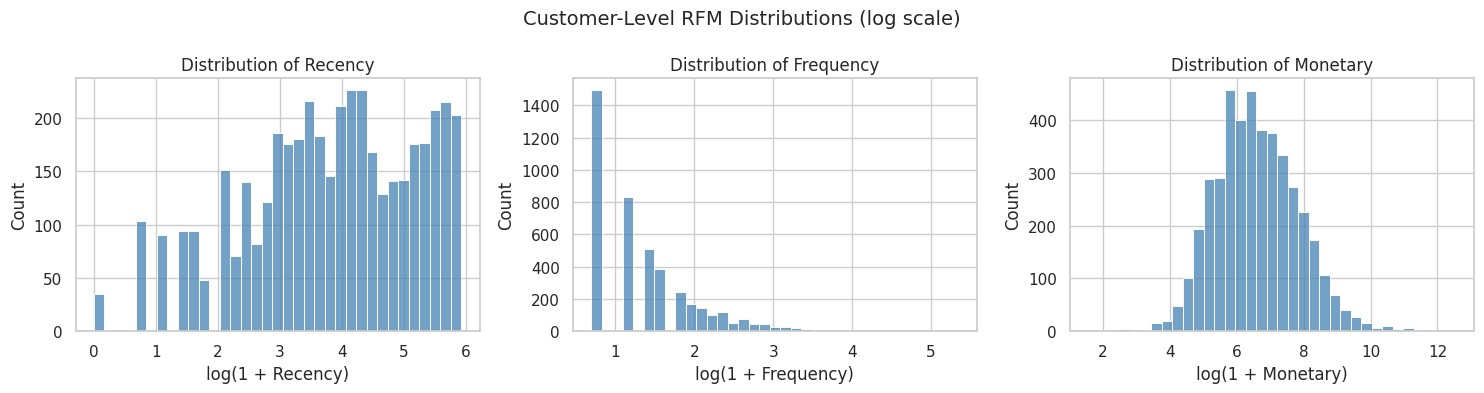

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(np.log1p(rfm[col].clip(lower=0)), bins=35, ax=ax, color="steelblue")
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_title(f"Distribution of {col}")
fig.suptitle("Customer-Level RFM Distributions (log scale)", fontsize=14)
fig.tight_layout()
fig.savefig("checkpoint_rfm_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

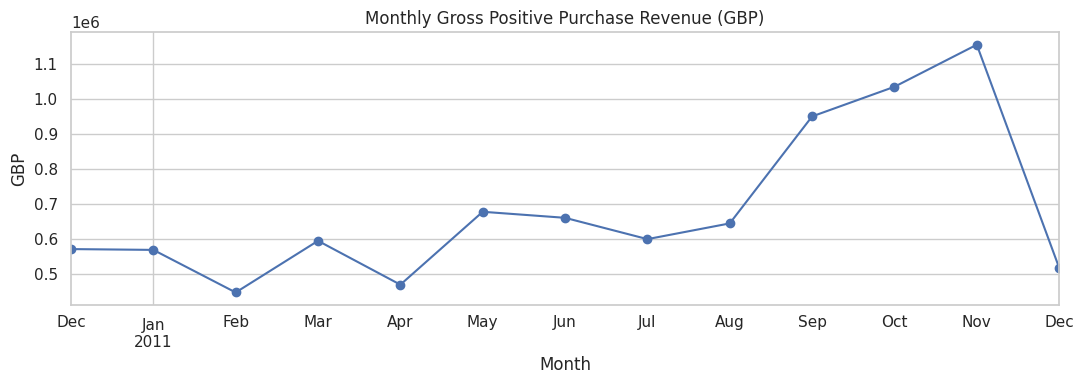

Note: first and last months are partial; cancellations excluded.


In [6]:
monthly = (purchases.assign(Month=purchases["InvoiceDate"].dt.to_period("M").dt.to_timestamp())
           .groupby("Month")["Revenue"].sum())
fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly Gross Positive Purchase Revenue (GBP)")
ax.set_ylabel("GBP")
fig.tight_layout()
fig.savefig("checkpoint_monthly_revenue.png", dpi=200, bbox_inches="tight")
plt.show()
print("Note: first and last months are partial; cancellations excluded.")

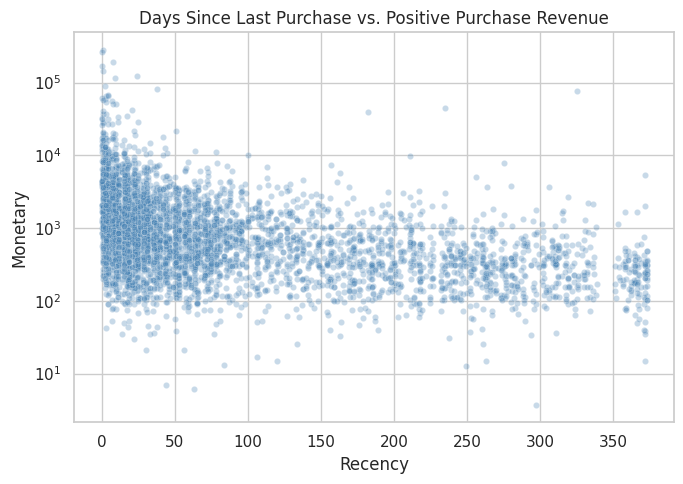

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", alpha=.3, s=20, ax=ax, color="steelblue")
ax.set_yscale("log")
ax.set_title("Days Since Last Purchase vs. Positive Purchase Revenue")
fig.tight_layout()
fig.savefig("checkpoint_recency_vs_spend.png", dpi=200, bbox_inches="tight")
plt.show()

## 5 · K-Means: RFM feature space and internal evaluation
We cluster on **Recency, Frequency, Monetary** only; average order value, basket size and cancellations are saved for **post-hoc interpretation**, avoiding correlated inputs being counted twice. Apply `log1p` for skew and standard scaling. Compare *k=2…6*. Use a fixed-size random sample for silhouette evaluation so this stays reproducible on a laptop. Silhouette is internal geometric evidence, **not a measure of business utility or truth**.

,k,sampled_silhouette,davies_bouldin,inertia
0,2,0.428,0.892,6488.007
1,3,0.329,1.048,4879.134
2,4,0.333,1.013,3962.703
3,5,0.319,0.995,3331.858
4,6,0.314,1.020,2875.401


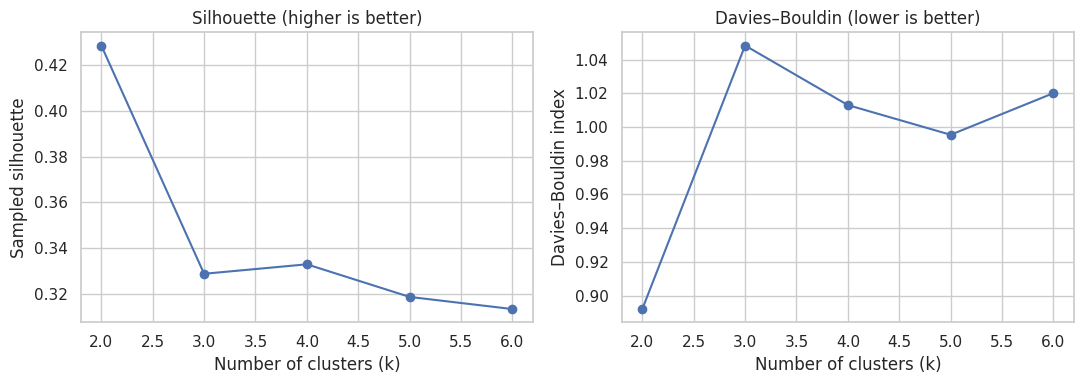

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

features = rfm[["Recency", "Frequency", "Monetary"]].clip(lower=0)
X = StandardScaler().fit_transform(np.log1p(features))
results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    results.append({"k": k,
                    "sampled_silhouette": silhouette_score(X, labels, sample_size=min(1500, len(X)), random_state=42),
                    "davies_bouldin": davies_bouldin_score(X, labels),
                    "inertia": model.inertia_})
score_table = pd.DataFrame(results)
display(score_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(score_table["k"], score_table["sampled_silhouette"], marker="o")
axes[0].set(xlabel="Number of clusters (k)", ylabel="Sampled silhouette", title="Silhouette (higher is better)")
axes[1].plot(score_table["k"], score_table["davies_bouldin"], marker="o")
axes[1].set(xlabel="Number of clusters (k)", ylabel="Davies–Bouldin index", title="Davies–Bouldin (lower is better)")
fig.tight_layout()
fig.savefig("final_model_selection.png", dpi=220, bbox_inches="tight")
plt.show()

In [9]:
best_k = int(score_table.loc[score_table["sampled_silhouette"].idxmax(), "k"])
rfm["Cluster"] = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X)
profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    MedianRecency=("Recency", "median"),
    MedianFrequency=("Frequency", "median"),
    MedianMonetary=("Monetary", "median"),
    MedianOrderValue=("AverageOrderValue", "median"),
    MedianBasketUnits=("BasketSizeUnits", "median"),
    MedianCancellationLines=("CancellationLineCount", "median"))
print("Selected k by sampled silhouette (not a guarantee of usefulness):", best_k)
display(profile.round(2))
profile.to_csv("final_cluster_profile.csv")

Selected k by sampled silhouette (not a guarantee of usefulness): 2


,Customers,MedianRecency,MedianFrequency,MedianMonetary,MedianOrderValue,MedianBasketUnits,MedianCancellationLines
Cluster,,,,,,,
0,1652,16.0,6.0,2077.92,346.50,203.21,1.0
1,2686,95.0,1.0,363.65,240.16,135.83,0.0


## 6 · Export data and summarize results
The customer-level file is **derived** from the authentic data. Avoid sharing CustomerID-level data publicly unless appropriate for the course. Use the aggregate profile and chart images for your recording.

In [10]:
rfm.drop(columns="Cluster", errors="ignore").to_csv("checkpoint_rfm_customer_features.csv")
print("Exported: checkpoint_rfm_customer_features.csv")
print("Charts: checkpoint_rfm_distributions.png, checkpoint_monthly_revenue.png, checkpoint_recency_vs_spend.png")
print("Optional: checkpoint_kmeans_silhouette.png, checkpoint_cluster_profile.csv")

Exported: checkpoint_rfm_customer_features.csv
Charts: checkpoint_rfm_distributions.png, checkpoint_monthly_revenue.png, checkpoint_recency_vs_spend.png
Optional: checkpoint_kmeans_silhouette.png, checkpoint_cluster_profile.csv


## 7 · Interpretation cautions
1. Customer labels are descriptions of observed **medians**, not causal explanations or true customer types.
2. Missing CustomerID and excluded cancellations may produce selection bias; purchase-only revenue is not net revenue.
3. Recency is relative to the **2011 snapshot**, not current date.
4. Retail data from a single historical seller may not generalize to other settings.
5. Silhouette measures separation in a transformed feature space; inspect the original feature distributions before deciding what clusters mean.
6. PCA is a **visual projection** of 3-D scaled RFM, not the clustering method itself.

**Citation:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

## 8 · Professor's request: plot every customer's assigned cluster
Each dot is a customer. The colors show **K-Means-assigned groups**, not known labels. PCA projects the scaled 3-D RFM features into two dimensions, making membership visible. The explained-variance percentages tell us how much RFM variation the plotted axes retain.

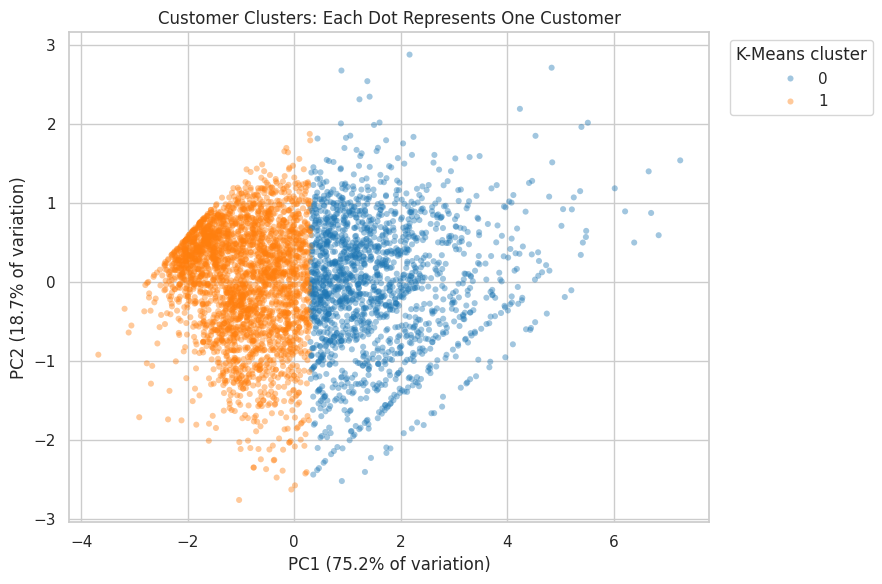

Total variation shown by both PCA axes: 93.9%


In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X)
cluster_plot = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1],
                             "Cluster": rfm["Cluster"].astype(str).to_numpy()})
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=cluster_plot, x="PC1", y="PC2", hue="Cluster",
                palette="tab10", alpha=0.42, s=19, linewidth=0, ax=ax)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variation)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variation)",
       title="Customer Clusters: Each Dot Represents One Customer")
ax.legend(title="K-Means cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("final_customer_clusters_pca.png", dpi=240, bbox_inches="tight")
plt.show()
print(f"Total variation shown by both PCA axes: {pca.explained_variance_ratio_.sum():.1%}")

### Original-variable cluster plot
PCA shows group membership but is harder to interpret. Here the same customers are displayed using **days since last purchase** and **positive purchase spending (£)**. Overlap is expected because K-Means used **three** input variables.

In [ ]:
# Scatter plot using original, interpretable RFM variables.
# Plot each cluster separately to avoid expensive automatic legend processing.
rfm_plot = rfm.reset_index().copy()
fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.get_cmap("tab10")
for j, cluster in enumerate(sorted(rfm_plot["Cluster"].unique())):
    group = rfm_plot.loc[rfm_plot["Cluster"] == cluster]
    ax.scatter(group["Recency"], group["Monetary"],
               label=f"Cluster {cluster}", color=colors(j), alpha=0.42,
               s=19, linewidths=0, rasterized=True)
ax.set_yscale("log")
ax.set(xlabel="Days since last purchase (2011 snapshot)",
       ylabel="Positive purchase spending (£, log scale)",
       title="Customer Groups in Original Business Variables")
ax.legend(title="K-Means cluster")
fig.tight_layout()
fig.savefig("final_customer_clusters_rfm.png", dpi=240, bbox_inches="tight")
plt.show()

## 9 · Interpretability: what behaviors explain the labels?
The following charts use **untransformed medians**, so the comparisons make sense to a business audience. **Lower Recency** indicates more recently active customers; **higher Frequency and Monetary** indicate more purchases and spending. A cluster number has no inherent business meaning; assign business names only after inspecting medians.

In [ ]:
profile_long = profile[["MedianRecency", "MedianFrequency", "MedianMonetary"]].copy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, label in zip(axes,
        ["MedianRecency", "MedianFrequency", "MedianMonetary"],
        ["Recency (days; lower = more recent)", "Frequency (invoices)", "Monetary (£)"]):
    vals = profile_long[col]
    ax.bar([f"Cluster {i}" for i in vals.index], vals.values)
    ax.set_title(label)
    for j, v in enumerate(vals.values):
        ax.annotate(f"{v:,.1f}", (j, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.set_ylim(0, max(vals.values) * 1.19 if len(vals) else 1)
fig.suptitle("What Makes Each Customer Group Interpretable?", fontsize=14)
fig.tight_layout()
fig.savefig("final_interpretable_rfm_profiles.png", dpi=240, bbox_inches="tight")
plt.show()
print("Naming guide: describe the RFM medians; do not assume customer motives or causal explanations.")

## 10 · Check whether cluster assignments are stable
A model with a convincing silhouette may still be sensitive to fitting choices. Refit K-Means for several random seeds and compare assignments against seed 42 using **adjusted Rand index (ARI)**. Here, ARI=1 means identical grouping (up to cluster-label permutation). This tests seed stability **on the same data**, not stability under new customers or time periods.

In [ ]:
from sklearn.metrics import adjusted_rand_score
baseline_labels = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X)
stability = []
for seed in [0, 1, 2, 7, 21, 42, 99]:
    trial_labels = KMeans(n_clusters=best_k, random_state=seed, n_init=10).fit_predict(X)
    stability.append({"Seed": seed, "ARI_vs_seed_42": adjusted_rand_score(baseline_labels, trial_labels)})
stability_table = pd.DataFrame(stability)
display(stability_table.round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(stability_table["Seed"], stability_table["ARI_vs_seed_42"], marker="o")
ax.set(xlabel="K-Means seed", ylabel="ARI vs seed 42", ylim=(-0.03, 1.04),
       title="Sensitivity to K-Means Random Initialization")
fig.tight_layout()
fig.savefig("final_cluster_seed_stability.png", dpi=220, bbox_inches="tight")
plt.show()

## 11 · Compare clustering methods on the *same* scaled RFM features
A comparison method helps determine whether customer groupings depend on K-Means specifically. Agglomerative clustering and Gaussian mixtures make different geometric assumptions. Compare **sampled silhouette and Davies–Bouldin**, alongside the cluster profiles and visuals. Higher silhouette alone is *not* an automatic reason to choose a model. All models use the K-Means-selected k here for controlled comparison.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

candidate_labels = {
    "K-Means": baseline_labels,
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X),
    "Gaussian mixture": GaussianMixture(n_components=best_k, random_state=42, n_init=3).fit_predict(X)
}
comparison = []
for method, labs in candidate_labels.items():
    comparison.append({
        "Method": method,
        "Clusters": len(np.unique(labs)),
        "SampledSilhouette": silhouette_score(X, labs, sample_size=min(1500, len(X)), random_state=42),
        "DaviesBouldin": davies_bouldin_score(X, labs),
        "ARIvsKMeans": adjusted_rand_score(baseline_labels, labs)
    })
comparison_table = pd.DataFrame(comparison)
display(comparison_table.round(3))
comparison_table.to_csv("final_method_comparison.csv", index=False)
# Note: a small cluster or a high score is not necessarily a useful segment.
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison_table["Method"], comparison_table["SampledSilhouette"])
ax.set(ylabel="Sampled silhouette (higher is better)", title="Method Comparison — Internal Separation")
ax.tick_params(axis="x", rotation=12)
fig.tight_layout()
fig.savefig("final_method_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 12 · Discussion prompts for the written report
After running the cells, fill in these statements using the **actual outputs**:

- **Selected k:** State the sampled silhouette and Davies–Bouldin for each candidate k; discuss whether the segments look meaningful in both plots.
- **Interpretability:** For each cluster, report customer count and RFM median; explain why the label follows from the observed behavior.
- **Trade-off:** Did another method score higher but produce groups that were harder to explain? If so, describe the evidence without claiming that a subjective label is objectively correct.
- **Stability:** Report the range of ARI across seeds; explain this limited notion of robustness.
- **Scope:** These are observational retail transactions, so the patterns are **associations**, not proof that a campaign would improve retention.
- **Limitations:** Historical data, missing IDs, cancelled orders excluded from purchase-only RFM, wholesale outliers, possible dependence on preprocessing, and no ground-truth labels.

For the presentation, use `final_customer_clusters_pca.png`, `final_customer_clusters_rfm.png`, `final_interpretable_rfm_profiles.png`, and `final_method_comparison.png`.

In [ ]:
print("Finished. Expected final outputs:")
for filename in ["final_customer_clusters_pca.png", "final_customer_clusters_rfm.png",
                 "final_interpretable_rfm_profiles.png", "final_model_selection.png",
                 "final_cluster_seed_stability.png", "final_method_comparison.png",
                 "final_cluster_profile.csv", "final_method_comparison.csv"]:
    print(" -", filename)
print("Use the charts and exact numeric outputs in your presentation and report.")